# 08. TN2: mô hình học ở khách sạn này có dùng được cho khách sạn kia không? (T14)

**Câu hỏi:** City Hotel (Lisbon) và Resort Hotel (Algarve) khác nhau về khách, giá, kênh đặt phòng và tỉ lệ hủy (`01_eda.ipynb`, Mục 5). Nếu chỉ có dữ liệu của một khách sạn, mô hình học từ đó có dự đoán tốt cho khách sạn còn lại không? Vì sao?

**Thiết kế** (`docs/decisions.md`, Mục 4.3):

| | Đánh giá trên test của City | Đánh giá trên test của Resort |
|---|---|---|
| **Train trên phần train của City** | City → City (cùng khách sạn) | City → Resort (chuyển khách sạn) |
| **Train trên phần train của Resort** | Resort → City (chuyển khách sạn) | Resort → Resort (cùng khách sạn) |

- **Giữ mốc chia theo thời gian** của cấu hình chính: train là các booking có ngày đến trước 01/01/2017, test là 07–08/2017. Mỗi mô hình chỉ học phần train của một khách sạn. Validation không dùng. Nhờ giữ nguyên mốc thời gian, chênh lệch đo được là do đổi khách sạn, không lẫn với ảnh hưởng của thời gian.
- **Bộ cột:** bộ sạch + `arrival_weekday` như cấu hình chính, **bỏ cột `hotel`**, vì khi chỉ train trên một khách sạn thì cột này là hằng số. Còn 22 cột.
- **Mô hình:** ba mô hình đã tinh chỉnh ở T10–T12, **giữ nguyên siêu tham số** trong `models/*.json`, không tinh chỉnh lại. TN2 không chọn tham số hay ngưỡng nào, nên kết quả trên test chỉ dùng để báo cáo.
- **Cách so:** với mỗi khách sạn đánh giá, so mô hình train cùng khách sạn với mô hình train ở khách sạn còn lại, trên **cùng một tập test**. Hai mô hình có cùng mốc PR-AUC (bằng tỉ lệ hủy của tập đó), nên chênh lệch đọc trực tiếp được. Không so PR-AUC thô giữa hai khách sạn đánh giá với nhau, vì mỗi tập có mốc riêng.

**Sản phẩm:**

- 12 dòng `experiment = "TN2"` trong `reports/results/results.csv` (3 mô hình × 2 khách sạn train × 2 khách sạn đánh giá).
- `reports/results/tn2_summary.csv`: 12 dòng trên và 6 dòng của phần kiểm soát cỡ dữ liệu (Mục 4).
- Hình `reports/figures/tn2_hotel_transfer.png` và `tn2_segment_calibration.png`.

## 0. Chuẩn bị

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from the project root or from notebooks/
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

RESULTS_PATH = ROOT / "reports" / "results" / "results.csv"
SUMMARY_PATH = ROOT / "reports" / "results" / "tn2_summary.csv"

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from src.config import CLEAN_CATEGORICAL_FEATURES, RANDOM_STATE, TARGET_COLUMN
from src.data import load_raw
from src.eda import save_figure
from src.evaluate import RESULT_COLUMNS, append_result, evaluate_classification
from src.features import ENGINEERED_CATEGORICAL_FEATURES, ENGINEERED_NUMERIC_FEATURES, add_features
from src.preprocess import build_model_pipeline, clean_data
from src.split import temporal_split

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)

TARGET = TARGET_COLUMN
HOTELS = ["City Hotel", "Resort Hotel"]
SHORT = {"City Hotel": "City", "Resort Hotel": "Resort"}
MODEL_NAMES = ["LogisticRegressionTuned", "RandomForest", "GradientBoosting"]
MODEL_LABELS = {"LogisticRegressionTuned": "LR", "RandomForest": "Random Forest", "GradientBoosting": "LightGBM"}
THRESHOLD = 0.5


def other_hotel(hotel: str) -> str:
    return next(h for h in HOTELS if h != hotel)

## 1. Dữ liệu và bộ cột

Luồng xử lý giống các notebook mô hình: `load_raw` → `clean_data` → `add_features` → `temporal_split`, sau đó tách theo cột `hotel`. Danh sách 13 biến số giống hệt notebook 03–07.

In [2]:
df = add_features(clean_data(load_raw()))
train, _valid, test = temporal_split(df, train_end="2017-01-01", valid_end="2017-07-01", date_col="arrival_date")
del _valid  # TN2 does not use the validation period

CLEAN_NUMERIC_FEATURES = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "adr", "total_of_special_requests",
]
NUMERIC_FEATURES = CLEAN_NUMERIC_FEATURES + list(ENGINEERED_NUMERIC_FEATURES)
# `hotel` is constant when a model is trained on one hotel only (docs/decisions.md, section 4.3)
CATEGORICAL_FEATURES = [
    c for c in list(CLEAN_CATEGORICAL_FEATURES) + list(ENGINEERED_CATEGORICAL_FEATURES) if c != "hotel"
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Columns that must never reach the model (docs/decisions.md, sections 3.1, 3.4 and 4.3)
FORBIDDEN = {
    TARGET, "hotel", "reservation_status", "reservation_status_date", "arrival_date",
    "arrival_date_year", "assigned_room_type", "booking_changes", "days_in_waiting_list",
    "deposit_type", "country", "required_car_parking_spaces",
}
assert len(FEATURES) == 22 and len(set(FEATURES)) == 22
assert not (set(FEATURES) & FORBIDDEN), "forbidden column in the feature list"
assert set(FEATURES) <= set(df.columns)

train_by_hotel = {h: train[train["hotel"].eq(h)] for h in HOTELS}
test_by_hotel = {h: test[test["hotel"].eq(h)] for h in HOTELS}
# temporal_split sorts by arrival_date and filtering keeps that order
assert all(p["arrival_date"].is_monotonic_increasing for p in [*train_by_hotel.values(), *test_by_hotel.values()])

overview = pd.DataFrame([
    {
        "hotel": h,
        "train_rows": len(train_by_hotel[h]),
        "train_cancel_rate": train_by_hotel[h][TARGET].mean(),
        "train_arrivals": f"{train_by_hotel[h]['arrival_date'].min():%d/%m/%Y} - {train_by_hotel[h]['arrival_date'].max():%d/%m/%Y}",
        "test_rows": len(test_by_hotel[h]),
        "test_cancel_rate": test_by_hotel[h][TARGET].mean(),
        "test_arrivals": f"{test_by_hotel[h]['arrival_date'].min():%d/%m/%Y} - {test_by_hotel[h]['arrival_date'].max():%d/%m/%Y}",
    }
    for h in HOTELS
]).set_index("hotel")
assert overview["train_rows"].tolist() == [51714, 26872]
assert overview["test_rows"].tolist() == [6679, 3554]
print(f"{len(FEATURES)} features: {len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical")
display(overview)

22 features: 13 numeric, 9 categorical


,train_rows,train_cancel_rate,train_arrivals,test_rows,test_cancel_rate,test_arrivals
hotel,,,,,,
City Hotel,51714,0.4138,01/07/2015 - 31/12/2016,6679,0.3661,01/07/2017 - 31/08/2017
Resort Hotel,26872,0.2629,01/07/2015 - 31/12/2016,3554,0.3807,01/07/2017 - 31/08/2017


**Nhận xét:**

- Hai khách sạn có cùng giai đoạn train (01/07/2015–31/12/2016) và cùng giai đoạn test (07–08/2017). Vì vậy chênh lệch giữa "cùng khách sạn" và "khách sạn còn lại" không lẫn với ảnh hưởng của thời gian.
- Train của City gần gấp đôi Resort: 51.714 so với 26.872 dòng. Mục 4 kiểm tra riêng ảnh hưởng của chênh lệch này.
- **Tỉ lệ hủy của Resort tăng mạnh theo thời gian:** 26,3% trong train nhưng 38,1% trong test, nên trong test Resort hủy nhiều hơn City (36,6%), ngược với train. Mọi mô hình đánh giá trên Resort đều gặp cùng sự thay đổi này (cùng các dòng test), nên phép so trong TN2 vẫn công bằng. Tuy vậy, sự thay đổi này ảnh hưởng đến các metric ở ngưỡng 0,5 (Mục 5.1).
- Mốc PR-AUC của hai tập test gần nhau (0,366 và 0,381), nhưng vẫn chỉ so các mô hình trên cùng một tập test.

## 2. Siêu tham số đã chốt

Đọc đúng ba file JSON mà notebook 04, 05, 06 đã lưu, và cũng là ba file TN1 dùng. Mỗi pipeline fit lại toàn bộ bước tiền xử lý (one-hot, gom mức hiếm, chuẩn hóa) **chỉ trên train của khách sạn được dùng để học**. Vì vậy các mức `agent`, `company`... mà mô hình nhận ra là các mức phổ biến ở khách sạn đó. Mục 5 sẽ xem điều này ảnh hưởng thế nào khi đổi khách sạn.

In [3]:
PARAMS_FILES = {
    "LogisticRegressionTuned": "logistic_regression_best_params.json",
    "RandomForest": "random_forest_best_params.json",
    "GradientBoosting": "gradient_boosting_best_params.json",
}
PARAMS = {
    name: json.loads((ROOT / "models" / file).read_text(encoding="utf-8"))
    for name, file in PARAMS_FILES.items()
}
ESTIMATORS = {
    "LogisticRegressionTuned": LogisticRegression,
    "RandomForest": RandomForestClassifier,
    "GradientBoosting": LGBMClassifier,
}


def make_pipeline(model_name: str):
    # Scaling only matters for the linear model; trees use the raw values
    return build_model_pipeline(
        train[FEATURES], ESTIMATORS[model_name](**PARAMS[model_name]),
        numeric_features=NUMERIC_FEATURES, categorical_features=CATEGORICAL_FEATURES,
        scale_numeric=(model_name == "LogisticRegressionTuned"),
    )


def evaluate_on(pipeline, eval_df: pd.DataFrame):
    # Metrics at the default threshold plus the mean predicted probability
    y_true = eval_df[TARGET]
    y_score = pipeline.predict_proba(eval_df[FEATURES])[:, 1]
    y_pred = (y_score >= THRESHOLD).astype(int)
    metrics = evaluate_classification(y_true, y_pred, y_score)
    return {"n_eval": len(eval_df), "eval_cancel_rate": float(y_true.mean()),
            "mean_pred": float(y_score.mean()), **metrics}, y_score


for name, params in PARAMS.items():
    print(f"{name}: {json.dumps(params, sort_keys=True)}")

LogisticRegressionTuned: {"C": 0.1, "class_weight": null, "max_iter": 3000, "penalty": "l2", "random_state": 42, "solver": "lbfgs"}
RandomForest: {"class_weight": "balanced_subsample", "max_depth": 20, "max_features": "sqrt", "min_samples_leaf": 20, "n_estimators": 300, "n_jobs": -1, "random_state": 42}
GradientBoosting: {"colsample_bytree": 0.9, "learning_rate": 0.05, "max_depth": -1, "min_child_samples": 30, "n_estimators": 300, "n_jobs": -1, "num_leaves": 31, "objective": "binary", "random_state": 42, "subsample": 0.9, "verbosity": -1}


## 3. Chạy TN2

Hai khách sạn train × ba mô hình = 6 pipeline. Mỗi pipeline được đánh giá trên test của cả hai khách sạn ở ngưỡng 0,5, tổng cộng 12 kết quả. PR-AUC và ROC-AUC tính từ xác suất dự đoán nên không phụ thuộc ngưỡng; F1, Precision, Recall tính ở ngưỡng 0,5. Cột `mean_pred` là xác suất hủy trung bình mô hình dự đoán, dùng ở Mục 5.

In [4]:
pipelines, scores, rows = {}, {}, []
for train_hotel in HOTELS:
    fit_df = train_by_hotel[train_hotel]
    for model_name in MODEL_NAMES:
        pipeline = make_pipeline(model_name).fit(fit_df[FEATURES], fit_df[TARGET])
        pipelines[(train_hotel, model_name)] = pipeline
        for eval_hotel in HOTELS:
            metrics, y_score = evaluate_on(pipeline, test_by_hotel[eval_hotel])
            scores[(train_hotel, model_name, eval_hotel)] = y_score
            rows.append({"model_name": model_name, "train_hotel": train_hotel, "train_variant": "full",
                         "n_train": len(fit_df), "eval_hotel": eval_hotel, **metrics})

tn2 = pd.DataFrame(rows)
tn2["direction"] = np.where(tn2["train_hotel"].eq(tn2["eval_hotel"]), "same hotel", "other hotel")
tn2["pair"] = tn2["train_hotel"].map(SHORT) + " -> " + tn2["eval_hotel"].map(SHORT)
assert len(tn2) == 12 and not tn2[["average_precision", "roc_auc", "f1"]].isna().any().any()

display(tn2.sort_values(["eval_hotel", "model_name", "direction"])[[
    "eval_hotel", "model_name", "pair", "n_eval", "eval_cancel_rate",
    "average_precision", "roc_auc", "f1", "precision", "recall", "mean_pred",
]].set_index(["eval_hotel", "model_name"]))

pair  n_eval  \
eval_hotel   model_name                                          
City Hotel   GradientBoosting           Resort -> City    6679   
             GradientBoosting             City -> City    6679   
             LogisticRegressionTuned    Resort -> City    6679   
             LogisticRegressionTuned      City -> City    6679   
             RandomForest               Resort -> City    6679   
             RandomForest                 City -> City    6679   
Resort Hotel GradientBoosting           City -> Resort    3554   
             GradientBoosting         Resort -> Resort    3554   
             LogisticRegressionTuned    City -> Resort    3554   
             LogisticRegressionTuned  Resort -> Resort    3554   
             RandomForest               City -> Resort    3554   
             RandomForest             Resort -> Resort    3554   

                                      eval_cancel_rate  average_precision  \
eval_hotel   model_name                                                     
City Hotel   GradientBoosting                   0.3661             0.5962   
             GradientBoosting                   0.3661             0.6821   
             LogisticRegressionTuned            0.3661             0.5780   
             LogisticRegressionTuned            0.3661             0.6705   
             RandomForest                       0.3661             0.6224   
             RandomForest                       0.3661             0.6721   
Resort Hotel GradientBoosting                   0.3807             0.5444   
             GradientBoosting                   0.3807             0.7327   
             LogisticRegressionTuned            0.3807             0.4988   
             LogisticRegressionTuned            0.3807             0.7395   
             RandomForest                       0.3807             0.5581   
             RandomForest                       0.3807             0.7267   

                                      roc_auc     f1  precision  recall  \
eval_hotel   model_name                                                   
City Hotel   GradientBoosting          0.7117 0.1423     0.8915  0.0773   
             GradientBoosting          0.7712 0.5721     0.6906  0.4883   
             LogisticRegressionTuned   0.6927 0.1743     0.7767  0.0982   
             LogisticRegressionTuned   0.7508 0.5939     0.6109  0.5779   
             RandomForest              0.7232 0.5118     0.6662  0.4155   
             RandomForest              0.7733 0.5478     0.6759  0.4605   
Resort Hotel GradientBoosting          0.6754 0.3256     0.6366  0.2188   
             GradientBoosting          0.8144 0.4365     0.8221  0.2971   
             LogisticRegressionTuned   0.6827 0.2808     0.4863  0.1973   
             LogisticRegressionTuned   0.8081 0.5151     0.8098  0.3777   
             RandomForest              0.6944 0.2744     0.6864  0.1715   
             RandomForest              0.8011 0.6586     0.6353  0.6837   

                                      mean_pred  
eval_hotel   model_name                          
City Hotel   GradientBoosting            0.2161  
             GradientBoosting            0.3332  
             LogisticRegressionTuned     0.2052  
             LogisticRegressionTuned     0.3974  
             RandomForest                0.3976  
             RandomForest                0.3903  
Resort Hotel GradientBoosting            0.2179  
             GradientBoosting            0.2587  
             LogisticRegressionTuned     0.2383  
             LogisticRegressionTuned     0.2899  
             RandomForest                0.2907  
             RandomForest                0.4458

baseline  pr_auc_same  pr_auc_other  \
eval_hotel   model_name                                                     
City Hotel   LogisticRegressionTuned    0.3661       0.6705        0.5780   
             RandomForest               0.3661       0.6721        0.6224   
             GradientBoosting           0.3661       0.6821        0.5962   
Resort Hotel LogisticRegressionTuned    0.3807       0.7395        0.4988   
             RandomForest               0.3807       0.7267        0.5581   
             GradientBoosting           0.3807       0.7327        0.5444   

                                      pr_auc_drop  excess_lost  roc_auc_same  \
eval_hotel   model_name                                                        
City Hotel   LogisticRegressionTuned       0.0925       0.3037        0.7508   
             RandomForest                  0.0498       0.1626        0.7733   
             GradientBoosting              0.0859       0.2719        0.7712   
Resort Hotel LogisticRegressionTuned       0.2407       0.6709        0.8081   
             RandomForest                  0.1686       0.4874        0.8011   
             GradientBoosting              0.1884       0.5351        0.8144   

                                      roc_auc_other  roc_auc_drop  
eval_hotel   model_name                                            
City Hotel   LogisticRegressionTuned         0.6927        0.0580  
             RandomForest                    0.7232        0.0502  
             GradientBoosting                0.7117        0.0594  
Resort Hotel LogisticRegressionTuned         0.6827        0.1254  
             RandomForest                    0.6944        0.1067  
             GradientBoosting                0.6754        0.1390

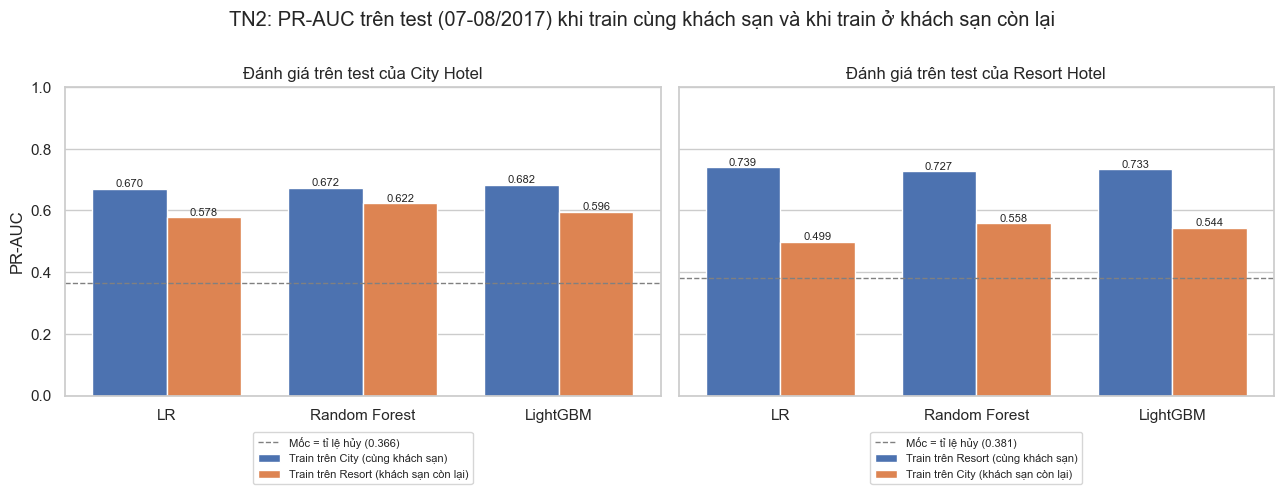

In [5]:
# Same evaluation rows on both sides, so both models share the same PR-AUC baseline
same = tn2[tn2["direction"].eq("same hotel")].set_index(["eval_hotel", "model_name"])
other = tn2[tn2["direction"].eq("other hotel")].set_index(["eval_hotel", "model_name"])
gap = pd.DataFrame({
    "baseline": same["eval_cancel_rate"],
    "pr_auc_same": same["average_precision"],
    "pr_auc_other": other["average_precision"],
    "pr_auc_drop": same["average_precision"] - other["average_precision"],
    "roc_auc_same": same["roc_auc"],
    "roc_auc_other": other["roc_auc"],
    "roc_auc_drop": same["roc_auc"] - other["roc_auc"],
}).reindex(pd.MultiIndex.from_product([HOTELS, MODEL_NAMES], names=["eval_hotel", "model_name"]))
# Share of the same-hotel model's PR-AUC above the baseline that is lost after switching hotel
gap.insert(4, "excess_lost", 1 - (gap["pr_auc_other"] - gap["baseline"]) / (gap["pr_auc_same"] - gap["baseline"]))
display(gap)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
x = np.arange(len(MODEL_NAMES))
width = 0.38
for ax, eval_hotel in zip(axes, HOTELS):
    part = gap.loc[eval_hotel]
    bars_same = ax.bar(x - width / 2, part["pr_auc_same"], width, color="#4C72B0",
                       label=f"Train trên {SHORT[eval_hotel]} (cùng khách sạn)")
    bars_other = ax.bar(x + width / 2, part["pr_auc_other"], width, color="#DD8452",
                        label=f"Train trên {SHORT[other_hotel(eval_hotel)]} (khách sạn còn lại)")
    ax.bar_label(bars_same, fmt="%.3f", fontsize=8)
    ax.bar_label(bars_other, fmt="%.3f", fontsize=8)
    baseline = part["baseline"].iloc[0]
    ax.axhline(baseline, color="grey", ls="--", lw=1, label=f"Mốc = tỉ lệ hủy ({baseline:.3f})")
    ax.set_xticks(x, [MODEL_LABELS[m] for m in MODEL_NAMES])
    ax.set_ylim(0, 1)
    ax.grid(False, axis="x")
    ax.set_title(f"Đánh giá trên test của {eval_hotel}")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=1)
axes[0].set_ylabel("PR-AUC")
fig.suptitle("TN2: PR-AUC trên test (07-08/2017) khi train cùng khách sạn và khi train ở khách sạn còn lại", y=1.0)
fig.tight_layout()
save_figure(fig, "tn2_hotel_transfer")
plt.show()

**Nhận xét:**

Cột `excess_lost` là phần vượt mốc bị mất: 1 − (PR-AUC khi train ở khách sạn còn lại − mốc) / (PR-AUC khi train cùng khách sạn − mốc). Ví dụ 0,30 nghĩa là mô hình mất 30% phần nó làm tốt hơn đoán ngẫu nhiên.

- **Đổi khách sạn luôn làm mô hình kém đi.** Cả 6 phép so (3 mô hình × 2 khách sạn đánh giá) đều giảm, ở cả PR-AUC lẫn ROC-AUC.
- **Mức giảm rất khác nhau giữa hai chiều:**
  - Đánh giá trên City (mô hình học ở Resort): PR-AUC giảm 0,050–0,093 (LR 0,670 → 0,578; Random Forest 0,672 → 0,622; LightGBM 0,682 → 0,596), mất 16–30% phần vượt mốc. ROC-AUC giảm 0,050–0,059.
  - Đánh giá trên Resort (mô hình học ở City): PR-AUC giảm 0,169–0,241 (LR 0,739 → 0,499; Random Forest 0,727 → 0,558; LightGBM 0,733 → 0,544), mất 49–67% phần vượt mốc. ROC-AUC giảm 0,107–0,139.

  Như vậy **chiều City → Resort mất nhiều hơn chiều Resort → City, ở cả ba mô hình.**
- **Mô hình vẫn hơn đoán ngẫu nhiên.** Ở chiều chuyển khách sạn, PR-AUC còn 0,578–0,622 trên City (mốc 0,366) và 0,499–0,558 trên Resort (mốc 0,381). Một phần quy luật hủy phòng là chung cho cả hai khách sạn.
- **Random Forest giảm ít nhất ở cả hai chiều**, Logistic Regression giảm nhiều nhất. Không có mô hình nào tránh được việc giảm.
- **Ở ngưỡng 0,5, hậu quả nặng hơn những gì PR-AUC cho thấy.** LR và LightGBM học ở Resort chỉ bắt được 9,8% và 7,7% số booking hủy của City (recall), so với 57,8% và 48,8% khi học ở City. Mục 5.1 giải thích vì sao.

## 4. Kiểm soát cỡ dữ liệu: khác khách sạn hay chỉ là ít dữ liệu hơn?

Train của City có 51.714 dòng, gần gấp đôi Resort (26.872 dòng). Nếu mô hình học ở Resort kém hơn khi dự đoán City, có hai cách giải thích: (1) Resort khác City, hoặc (2) Resort chỉ đơn giản là có ít dữ liệu hơn.

Để tách hai nguyên nhân, lấy ngẫu nhiên 26.872 dòng từ train của City (`random_state=42`, sau đó sắp lại theo ngày đến), huấn luyện lại ba mô hình rồi đánh giá trên cùng hai tập test. Mẫu ngẫu nhiên vẫn trải đều 07/2015–12/2016 như train đầy đủ, nên chỉ có cỡ dữ liệu thay đổi. Phần này không ghi vào `results.csv` (không phải một ô của thiết kế TN2), chỉ ghi vào `tn2_summary.csv`.

In [6]:
n_resort = len(train_by_hotel["Resort Hotel"])
city_small = (train_by_hotel["City Hotel"].sample(n=n_resort, random_state=RANDOM_STATE)
              .sort_values("arrival_date", kind="mergesort"))
assert len(city_small) == n_resort
print(f"City train subsample: {len(city_small):,} rows, cancellation rate {city_small[TARGET].mean():.4f} "
      f"(full City train: {train_by_hotel['City Hotel'][TARGET].mean():.4f})")

small_rows = []
for model_name in MODEL_NAMES:
    pipeline = make_pipeline(model_name).fit(city_small[FEATURES], city_small[TARGET])
    for eval_hotel in HOTELS:
        metrics, _ = evaluate_on(pipeline, test_by_hotel[eval_hotel])
        small_rows.append({"model_name": model_name, "train_hotel": "City Hotel", "train_variant": "size_matched",
                           "n_train": len(city_small), "eval_hotel": eval_hotel, **metrics})
size_matched = pd.DataFrame(small_rows)

both = pd.concat([tn2.drop(columns=["direction", "pair"]), size_matched], ignore_index=True)
both["trained_on"] = (both["train_hotel"].map(SHORT) + ", "
                      + np.where(both["train_variant"].eq("size_matched"), "subsample", "full")
                      + " (n=" + both["n_train"].astype(str) + ")")
order = [f"City, full (n={len(train_by_hotel['City Hotel'])})", f"City, subsample (n={n_resort})",
         f"Resort, full (n={n_resort})"]
size_table = (both.pivot_table(index=["eval_hotel", "model_name"], columns="trained_on",
                               values=["average_precision", "roc_auc"])
              .reindex(columns=order, level=1)
              .reindex(pd.MultiIndex.from_product([HOTELS, MODEL_NAMES], names=["eval_hotel", "model_name"])))
display(size_table)

City train subsample: 26,872 rows, cancellation rate 0.4141 (full City train: 0.4138)


average_precision  \
trained_on                           City, full (n=51714)   
eval_hotel   model_name                                     
City Hotel   LogisticRegressionTuned               0.6705   
             RandomForest                          0.6721   
             GradientBoosting                      0.6821   
Resort Hotel LogisticRegressionTuned               0.4988   
             RandomForest                          0.5581   
             GradientBoosting                      0.5444   

                                                                \
trained_on                           City, subsample (n=26872)   
eval_hotel   model_name                                          
City Hotel   LogisticRegressionTuned                    0.6692   
             RandomForest                               0.6701   
             GradientBoosting                           0.6796   
Resort Hotel LogisticRegressionTuned                    0.5149   
             RandomForest                               0.5626   
             GradientBoosting                           0.5395   

                                                             \
trained_on                           Resort, full (n=26872)   
eval_hotel   model_name                                       
City Hotel   LogisticRegressionTuned                 0.5780   
             RandomForest                            0.6224   
             GradientBoosting                        0.5962   
Resort Hotel LogisticRegressionTuned                 0.7395   
             RandomForest                            0.7267   
             GradientBoosting                        0.7327   

                                                  roc_auc  \
trained_on                           City, full (n=51714)   
eval_hotel   model_name                                     
City Hotel   LogisticRegressionTuned               0.7508   
             RandomForest                          0.7733   
             GradientBoosting                      0.7712   
Resort Hotel LogisticRegressionTuned               0.6827   
             RandomForest                          0.6944   
             GradientBoosting                      0.6754   

                                                                \
trained_on                           City, subsample (n=26872)   
eval_hotel   model_name                                          
City Hotel   LogisticRegressionTuned                    0.7516   
             RandomForest                               0.7676   
             GradientBoosting                           0.7701   
Resort Hotel LogisticRegressionTuned                    0.6922   
             RandomForest                               0.7056   
             GradientBoosting                           0.6673   

                                                             
trained_on                           Resort, full (n=26872)  
eval_hotel   model_name                                      
City Hotel   LogisticRegressionTuned                 0.6927  
             RandomForest                            0.7232  
             GradientBoosting                        0.7117  
Resort Hotel LogisticRegressionTuned                 0.8081  
             RandomForest                            0.8011  
             GradientBoosting                        0.8144

**Nhận xét:**

- Mẫu 26.872 dòng của City có tỉ lệ hủy 41,41%, gần như bằng train đầy đủ (41,38%).
- **Giảm một nửa dữ liệu City gần như không ảnh hưởng.** Trên test của City, PR-AUC chỉ giảm tối đa 0,003 (LR 0,671 → 0,669; Random Forest 0,672 → 0,670; LightGBM 0,682 → 0,680).
- **Khi hai bên có cùng 26.872 dòng, khoảng cách vẫn còn gần như nguyên vẹn.** Trên test của City, mô hình học từ mẫu City đạt 0,669–0,680, còn mô hình học ở Resort chỉ đạt 0,578–0,622. Khoảng cách 0,048–0,091, so với 0,050–0,093 khi City dùng đủ dữ liệu.
- Trên test của Resort, mô hình học từ mẫu City thay đổi từ −0,005 đến +0,016 so với khi học trên City đầy đủ, không theo một chiều nhất định, và vẫn thấp hơn nhiều so với mô hình học ở Resort. Có thêm dữ liệu City cũng không giúp mô hình dùng tốt hơn cho Resort.
- **Kết luận:** chênh lệch ở Mục 3 do hai khách sạn khác nhau, không phải do Resort có ít dữ liệu hơn. Ở cỡ dữ liệu này (khoảng 27 nghìn dòng trở lên), lượng dữ liệu không phải là yếu tố giới hạn.

## 5. Vì sao mô hình chuyển được hoặc không chuyển được?

EDA (Mục 5) đã thấy hai kiểu khác biệt giữa hai khách sạn:

- **Covariate shift** (dịch chuyển phân bố đặc trưng): cơ cấu khách, giá, kênh đặt phòng khác nhau.
- **Concept shift** (thay đổi quan hệ đặc trưng → hủy): cùng một phân khúc nhưng tỉ lệ hủy ở hai khách sạn khác nhau.

Ba kiểm tra dưới đây xem các khác biệt đó thể hiện trong dự đoán ra sao:

- (a) mô hình đoán mức hủy chung quá cao hay quá thấp;
- (b) đoán lệch ở phân khúc nào;
- (c) bao nhiêu giá trị phân loại của khách sạn kia mà mô hình "không nhận ra".

### 5.1. Mức hủy chung: xác suất dự đoán trung bình so với tỉ lệ hủy thật

Nếu mô hình chỉ xếp hạng tốt nhưng đoán sai mức hủy chung, PR-AUC vẫn có thể giữ được, nhưng Precision và Recall ở ngưỡng cố định 0,5 sẽ lệch. Lưu ý: Random Forest dùng `class_weight="balanced_subsample"`, nên xác suất của nó bị đẩy lên so với tỉ lệ hủy thật ngay cả khi train cùng khách sạn. Vì vậy với mỗi mô hình, so chiều chuyển khách sạn với chiều cùng khách sạn của **chính mô hình đó**, không so trực tiếp với tỉ lệ hủy thật.

In [7]:
train_rates = pd.Series({h: train_by_hotel[h][TARGET].mean() for h in HOTELS}, name="train_cancel_rate")
print("Cancellation rate in each hotel's training data:")
display(train_rates.to_frame())

calib = (tn2.pivot_table(index=["eval_hotel", "train_hotel"], columns="model_name", values="mean_pred")
         [MODEL_NAMES].add_prefix("mean_pred_"))
calib.insert(0, "actual_cancel_rate", tn2.groupby(["eval_hotel", "train_hotel"])["eval_cancel_rate"].first())
display(calib)

pr_table = (tn2.pivot_table(index=["eval_hotel", "train_hotel"], columns="model_name", values=["precision", "recall"])
            .reindex(columns=MODEL_NAMES, level=1))
display(pr_table)

Cancellation rate in each hotel's training data:


,train_cancel_rate
City Hotel,0.4138
Resort Hotel,0.2629


model_name                 actual_cancel_rate  \
eval_hotel   train_hotel                        
City Hotel   City Hotel                0.3661   
             Resort Hotel              0.3661   
Resort Hotel City Hotel                0.3807   
             Resort Hotel              0.3807   

model_name                 mean_pred_LogisticRegressionTuned  \
eval_hotel   train_hotel                                       
City Hotel   City Hotel                               0.3974   
             Resort Hotel                             0.2052   
Resort Hotel City Hotel                               0.2383   
             Resort Hotel                             0.2899   

model_name                 mean_pred_RandomForest  mean_pred_GradientBoosting  
eval_hotel   train_hotel                                                       
City Hotel   City Hotel                    0.3903                      0.3332  
             Resort Hotel                  0.3976                      0.2161  
Resort Hotel City Hotel                    0.2907                      0.2179  
             Resort Hotel                  0.4458                      0.2587

precision               \
model_name                LogisticRegressionTuned RandomForest   
eval_hotel   train_hotel                                         
City Hotel   City Hotel                    0.6109       0.6759   
             Resort Hotel                  0.7767       0.6662   
Resort Hotel City Hotel                    0.4863       0.6864   
             Resort Hotel                  0.8098       0.6353   

                                                            recall  \
model_name                GradientBoosting LogisticRegressionTuned   
eval_hotel   train_hotel                                             
City Hotel   City Hotel             0.6906                  0.5779   
             Resort Hotel           0.8915                  0.0982   
Resort Hotel City Hotel             0.6366                  0.1973   
             Resort Hotel           0.8221                  0.3777   

                                                         
model_name                RandomForest GradientBoosting  
eval_hotel   train_hotel                                 
City Hotel   City Hotel         0.4605           0.4883  
             Resort Hotel       0.4155           0.0773  
Resort Hotel City Hotel         0.1715           0.2188  
             Resort Hotel       0.6837           0.2971

### 5.2. Theo phân khúc thị trường (LightGBM)

Chỉ xét LightGBM, mô hình có PR-AUC cao nhất trên validation trong cấu hình chính (`results.csv`), và chỉ các phân khúc có ít nhất 100 booking trong tập test được xét. Groups chỉ có 5 booking trong test của Resort nên không xét được ở Resort. Cột `train_rate_*` là tỉ lệ hủy của phân khúc đó trong train của từng khách sạn, tức là điều mỗi mô hình "đã thấy".

n  actual  pred_same_hotel  pred_other_hotel  \
eval_hotel   market_segment                                                    
City Hotel   Online TA       4465  0.4260           0.3705            0.2169   
             Offline TA/TO    934  0.2591           0.2550            0.1842   
             Direct           719  0.1599           0.1732            0.1635   
             Groups           412  0.4126           0.4629            0.3936   
             Corporate        123  0.0976           0.1214            0.1667   
Resort Hotel Online TA       2267  0.4680           0.3261            0.2037   
             Direct           656  0.2287           0.1355            0.1770   
             Offline TA/TO    548  0.1898           0.1277            0.3199   

                             train_rate_City  train_rate_Resort  
eval_hotel   market_segment                                      
City Hotel   Online TA                0.3487             0.3215  
             Offline TA/TO            0.4299             0.1459  
             Direct                   0.1827             0.1276  
             Groups                   0.7010             0.4504  
             Corporate                0.1832             0.1249  
Resort Hotel Online TA                0.3487             0.3215  
             Direct                   0.1827             0.1276  
             Offline TA/TO            0.4299             0.1459

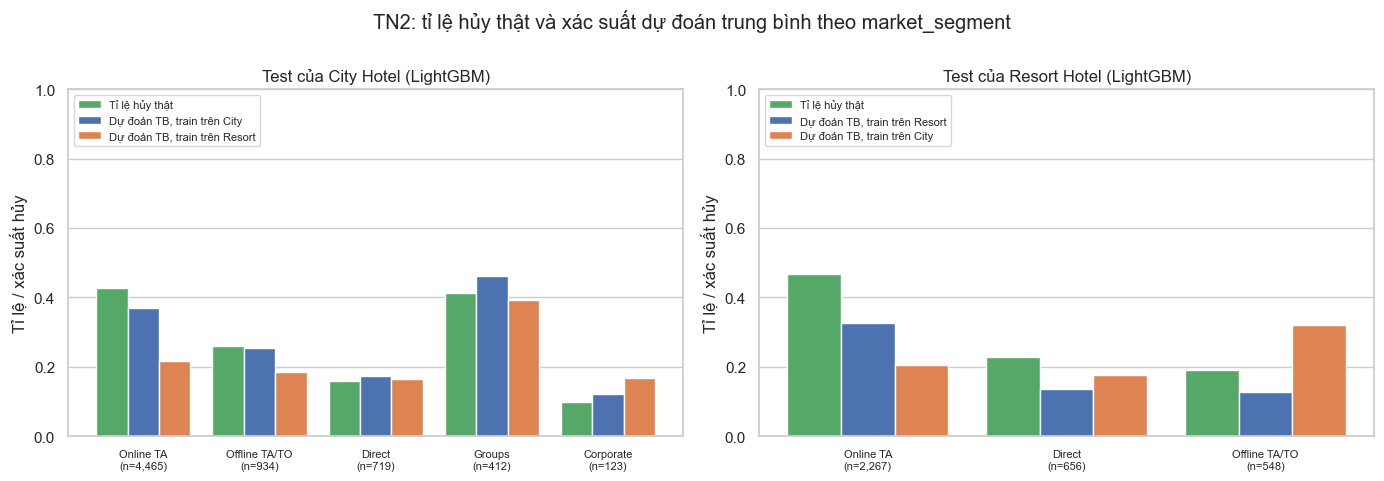

In [8]:
MAIN_MODEL = "GradientBoosting"
seg_parts = []
for eval_hotel in HOTELS:
    eval_df = test_by_hotel[eval_hotel]
    frame = pd.DataFrame({
        "market_segment": eval_df["market_segment"].to_numpy(),
        "actual": eval_df[TARGET].to_numpy(),
        "pred_same_hotel": scores[(eval_hotel, MAIN_MODEL, eval_hotel)],
        "pred_other_hotel": scores[(other_hotel(eval_hotel), MAIN_MODEL, eval_hotel)],
    })
    seg = frame.groupby("market_segment").agg(
        n=("actual", "size"), actual=("actual", "mean"),
        pred_same_hotel=("pred_same_hotel", "mean"), pred_other_hotel=("pred_other_hotel", "mean"),
    )
    seg = seg[seg["n"] >= 100].sort_values("n", ascending=False)
    for h in HOTELS:
        seg[f"train_rate_{SHORT[h]}"] = (train_by_hotel[h].groupby("market_segment")[TARGET].mean()
                                         .reindex(seg.index))
    seg_parts.append(seg.assign(eval_hotel=eval_hotel).reset_index())
segment_table = pd.concat(seg_parts).set_index(["eval_hotel", "market_segment"])
display(segment_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, eval_hotel in zip(axes, HOTELS):
    part = segment_table.loc[eval_hotel]
    x = np.arange(len(part))
    width = 0.27
    ax.bar(x - width, part["actual"], width, color="#55A868", label="Tỉ lệ hủy thật")
    ax.bar(x, part["pred_same_hotel"], width, color="#4C72B0",
           label=f"Dự đoán TB, train trên {SHORT[eval_hotel]}")
    ax.bar(x + width, part["pred_other_hotel"], width, color="#DD8452",
           label=f"Dự đoán TB, train trên {SHORT[other_hotel(eval_hotel)]}")
    ax.set_xticks(x, [f"{s}\n(n={n:,})" for s, n in zip(part.index, part["n"])], fontsize=8)
    ax.set_ylim(0, 1)
    ax.grid(False, axis="x")
    ax.set_ylabel("Tỉ lệ / xác suất hủy")
    ax.set_title(f"Test của {eval_hotel} (LightGBM)")
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("TN2: tỉ lệ hủy thật và xác suất dự đoán trung bình theo market_segment", y=1.0)
fig.tight_layout()
save_figure(fig, "tn2_segment_calibration")
plt.show()

### 5.3. Mô hình có "nhận ra" các giá trị phân loại của khách sạn kia không?

Bộ mã hóa one-hot (`min_frequency=0.01`) chỉ tạo cột riêng cho các mức chiếm ít nhất 1% train của khách sạn được dùng để học; các mức khác bị gom vào một cột "hiếm" chung. Bảng dưới tính, với mỗi cột phân loại, tỉ lệ booking trong test của khách sạn đánh giá có giá trị nằm trong các mức có cột riêng. Cột `covered_same` là khi encoder học ở cùng khách sạn, `covered_other` là khi học ở khách sạn còn lại. Bộ mã hóa giống nhau ở cả ba mô hình (chỉ phụ thuộc dữ liệu train), nên lấy từ pipeline LightGBM.

In [9]:
def frequent_levels(pipeline) -> dict[str, set]:
    # Categories that got their own one-hot column (not grouped as infrequent)
    onehot = pipeline.named_steps["preprocessor"].named_transformers_["categorical"].named_steps["onehot"]
    levels = {}
    for col, cats, infrequent in zip(CATEGORICAL_FEATURES, onehot.categories_, onehot.infrequent_categories_):
        levels[col] = set(cats) - (set() if infrequent is None else set(infrequent))
    return levels


levels = {h: frequent_levels(pipelines[(h, MAIN_MODEL)]) for h in HOTELS}
cov_rows = []
for eval_hotel in HOTELS:
    eval_df = test_by_hotel[eval_hotel]
    for col in CATEGORICAL_FEATURES:
        values = eval_df[col].astype(str)
        cov_rows.append({
            "eval_hotel": eval_hotel, "column": col,
            "levels_same": len(levels[eval_hotel][col]),
            "covered_same": values.isin(levels[eval_hotel][col]).mean(),
            "levels_other": len(levels[other_hotel(eval_hotel)][col]),
            "covered_other": values.isin(levels[other_hotel(eval_hotel)][col]).mean(),
        })
coverage = pd.DataFrame(cov_rows).set_index(["eval_hotel", "column"])
display(coverage)

# Agent codes only: bookings that went through an agent
for eval_hotel in HOTELS:
    booked = test_by_hotel[eval_hotel].loc[lambda d: d["agent"].ne("none"), "agent"].astype(str)
    same_cov = booked.isin(levels[eval_hotel]["agent"] - {"none"}).mean()
    other_cov = booked.isin(levels[other_hotel(eval_hotel)]["agent"] - {"none"}).mean()
    print(f"{eval_hotel} test, {len(booked):,} agent bookings: agent code recognised by "
          f"same-hotel encoder {same_cov:.1%}, other-hotel encoder {other_cov:.1%}")

levels_same  covered_same  levels_other  \
eval_hotel   column                                                          
City Hotel   arrival_date_month             12        1.0000            12   
             meal                            3        1.0000             4   
             market_segment                  5        0.9961             5   
             distribution_channel            3        0.9994             3   
             reserved_room_type              5        0.9876             7   
             customer_type                   3        0.9979             3   
             agent                          14        0.8464            13   
             company                         2        0.9895             2   
             arrival_weekday                 7        1.0000             7   
Resort Hotel arrival_date_month             12        1.0000            12   
             meal                            4        1.0000             3   
             market_segment                  5        0.9972             5   
             distribution_channel            3        1.0000             3   
             reserved_room_type              7        1.0000             5   
             customer_type                   3        0.9899             3   
             agent                          13        0.8739            14   
             company                         2        0.9856             2   
             arrival_weekday                 7        1.0000             7   

                                   covered_other  
eval_hotel   column                               
City Hotel   arrival_date_month           1.0000  
             meal                         1.0000  
             market_segment               0.9961  
             distribution_channel         0.9994  
             reserved_room_type           0.9892  
             customer_type                0.9979  
             agent                        0.1150  
             company                      0.9793  
             arrival_weekday              1.0000  
Resort Hotel arrival_date_month           1.0000  
             meal                         0.9845  
             market_segment               0.9972  
             distribution_channel         1.0000  
             reserved_room_type           0.8486  
             customer_type                0.9899  
             agent                        0.0965  
             company                      0.9865  
             arrival_weekday              1.0000

City Hotel test, 6,236 agent bookings: agent code recognised by same-hotel encoder 83.5%, other-hotel encoder 5.2%
Resort Hotel test, 3,258 agent bookings: agent code recognised by same-hotel encoder 86.2%, other-hotel encoder 1.4%


Một mã đại lý không được nhận ra sẽ rơi vào cột "hiếm". Ý nghĩa của cột này do dữ liệu train quyết định: đó là các đại lý nhỏ của khách sạn đã học. Ô dưới xem nhóm "đại lý hiếm" trong train của mỗi khách sạn hủy bao nhiêu, xét riêng Online TA (phân khúc lớn nhất trong test của cả hai khách sạn), và đại lý chính của Online TA trong mỗi tập test là ai.

In [10]:
bucket_rows = []
for h in HOTELS:
    t = train_by_hotel[h]
    online = t["market_segment"].eq("Online TA")
    infrequent = ~t["agent"].astype(str).isin(levels[h]["agent"])
    bucket_rows.append({
        "train_hotel": h,
        "online_ta_rows": int(online.sum()),
        "online_ta_cancel_rate": t.loc[online, TARGET].mean(),
        "online_ta_infrequent_agent_rows": int((online & infrequent).sum()),
        "online_ta_infrequent_agent_cancel_rate": t.loc[online & infrequent, TARGET].mean(),
    })
display(pd.DataFrame(bucket_rows).set_index("train_hotel"))

for h in HOTELS:
    online_agents = test_by_hotel[h].loc[lambda d: d["market_segment"].eq("Online TA"), "agent"].astype(str)
    top = online_agents.value_counts(normalize=True).head(2)
    recognised = online_agents.isin(levels[other_hotel(h)]["agent"]).mean()
    print(f"{h} test, Online TA ({len(online_agents):,} bookings): top agents "
          + ", ".join(f"{code} ({share:.1%})" for code, share in top.items())
          + f"; recognised by the {SHORT[other_hotel(h)]} encoder: {recognised:.1%}")

,online_ta_rows,online_ta_cancel_rate,online_ta_infrequent_agent_rows,online_ta_infrequent_agent_cancel_rate
train_hotel,,,,
City Hotel,22731,0.3487,1013,0.1609
Resort Hotel,11055,0.3215,322,0.1429


City Hotel test, Online TA (4,465 bookings): top agents 9.0 (85.3%), 7.0 (6.1%); recognised by the Resort encoder: 0.3%
Resort Hotel test, Online TA (2,267 bookings): top agents 240.0 (70.8%), 241.0 (12.7%); recognised by the City encoder: 0.4%


**Nhận xét:**

**5.1. Mức hủy chung**

- **Resort → City: LR và LightGBM đoán mức hủy quá thấp.**
  - Xác suất trung bình chỉ 0,205 và 0,216, so với 0,397 và 0,333 của mô hình học ở City (tỉ lệ hủy thật 0,366). Mô hình học ở khách sạn có tỉ lệ hủy 26,3% nên mang theo mức đó.
  - Ở ngưỡng 0,5, hai mô hình chỉ báo hủy với số ít booking chắc chắn nhất: precision cao (0,777 và 0,892) nhưng recall chỉ 0,098 và 0,077.
- **Random Forest là ngoại lệ ở chiều này.** Xác suất trung bình 0,398, gần bằng mô hình học ở City (0,390); recall 0,416 so với 0,461. Lý do hợp lý: `class_weight="balanced_subsample"` cân bằng hai lớp khi học, nên mức xác suất ít phụ thuộc tỉ lệ hủy của khách sạn train. Tuy vậy ở chiều ngược lại, Random Forest cũng giảm mạnh (recall 0,684 → 0,172), nên cân bằng lớp không giải quyết được việc đổi khách sạn.
- **City → Resort: mô hình không đoán cao như EDA dự đoán, mà đoán thấp hơn.** Cả ba mô hình học ở City cho xác suất trung bình trên Resort thấp hơn mô hình học ở Resort: LR 0,238 so với 0,290; Random Forest 0,291 so với 0,446; LightGBM 0,218 so với 0,259 (thật 0,381). Recall giảm theo: LR 0,378 → 0,197; Random Forest 0,684 → 0,172; LightGBM 0,297 → 0,219.
- **Ghi chú:** ngay cả mô hình học ở Resort cũng đoán thấp hơn tỉ lệ thật của test Resort (LightGBM 0,259 so với 0,381), vì tỉ lệ hủy của Resort đã tăng từ 26,3% lên 38,1% (Mục 1). Nguyên nhân ở đây là thời gian, không phải đổi khách sạn. Đây là lý do nên chọn lại ngưỡng (TN3) thay vì dùng 0,5.

**5.2. Theo phân khúc (LightGBM)**

- **Offline TA/TO khớp với concept shift mà EDA đã thấy.** Trong train, phân khúc này ở City hủy 43,0%, ở Resort chỉ 14,6%.
  - Mô hình City đoán Offline TA/TO của Resort là 0,320, cao hơn tỉ lệ thật 0,190 (mô hình Resort: 0,128).
  - Ngược lại, mô hình Resort đoán Offline TA/TO của City 0,184, thấp hơn tỉ lệ thật 0,259 (mô hình City: 0,255).
- **Sai lệch lớn nhất lại nằm ở Online TA**, phân khúc lớn nhất trong cả hai tập test (4.465 booking ở City, 2.267 ở Resort).
  - Mô hình khách sạn còn lại đoán 0,217 (thật 0,426) ở City và 0,204 (thật 0,468) ở Resort, thấp hơn nhiều so với mô hình cùng khách sạn (0,371 và 0,326).
  - Trong khi đó, tỉ lệ hủy của Online TA trong train hai khách sạn gần như bằng nhau (34,9% và 32,2%). Vì vậy sai lệch này không đến từ cột `market_segment` mà từ các cột khác, xem 5.3.

**5.3. Mã đại lý không trùng giữa hai khách sạn**

- Hầu hết các cột phân loại được nhận ra gần như đầy đủ dù encoder học ở khách sạn nào (≥ 97,9% booking). Có hai ngoại lệ:
  - **`agent`:** trong các booking qua đại lý, encoder cùng khách sạn nhận ra 83,5% (City) và 86,2% (Resort) mã đại lý, còn encoder của khách sạn kia chỉ 5,2% và 1,4%. Hai khách sạn gần như làm việc với hai bộ đại lý khác nhau.
  - **`reserved_room_type` khi đánh giá trên Resort:** encoder City chỉ nhận ra loại phòng của 84,9% booking Resort (encoder Resort: 100%). Khoảng 15% booking Resort đặt loại phòng mà City hầu như không có. Chiều ngược lại không gặp vấn đề này (98,9%).
- **Cách mã đại lý làm mô hình đoán thấp ở Online TA:**
  - Online TA của mỗi khách sạn chủ yếu đi qua một đại lý: City là đại lý 9 (85,3%), Resort là đại lý 240 (70,8%). Encoder của khách sạn kia chỉ nhận ra 0,3% và 0,4% mã đại lý của nhóm này, nên gần như toàn bộ rơi vào cột "đại lý hiếm".
  - Trong train, Online TA qua "đại lý hiếm" chỉ hủy 16,1% (City, 1.013 booking) và 14,3% (Resort, 322 booking), thấp hơn nhiều mức chung của Online TA (34,9% và 32,2%).
  - Nói cách khác, với mô hình đã học, "đại lý hiếm" nghĩa là "đại lý nhỏ, ít hủy". Ở khách sạn kia, cùng cột đó lại chứa đại lý lớn nhất, có tỉ lệ hủy cao. Điều này giải thích hợp lý việc mô hình đoán thấp Online TA ở cả hai chiều.
- **Mức chắc chắn:** đây là bằng chứng gián tiếp, đối chiếu tỉ lệ chứ chưa chứng minh nhân quả. Muốn chắc chắn cần chạy lại TN2 sau khi bỏ cột `agent`; notebook này chưa làm.
- **Vì sao chiều City → Resort mất nhiều hơn?** TN2 không tách được chính xác. Các dấu hiệu:
  1. 15% booking Resort đặt loại phòng mà mô hình City không nhận ra, trong khi chiều ngược lại gần như không có.
  2. Mô hình City đoán sai Offline TA/TO của Resort theo hướng cao.
  3. Trên chính khách sạn của mình, mô hình Resort vượt mốc nhiều hơn mô hình City (khoảng 0,35 so với 0,30–0,32), nên mức giảm *tuyệt đối* lớn hơn một phần cũng vì vậy. Tuy nhiên điều này không giải thích được tỉ lệ bị mất cao hơn (49–67% so với 16–30%).

  Lượng dữ liệu thì đã bị loại khỏi danh sách nguyên nhân (Mục 4).

### 5.4. Đối chiếu với dự đoán ghi trước ở EDA

`01_eda.ipynb` (Mục 5) đã ghi 5 dự đoán cho TN2 **trước khi** chạy mô hình. Bảng dưới đối chiếu từng dự đoán với kết quả:

| # | Dự đoán của EDA | Kết quả TN2 | Đánh giá |
|---|---|---|---|
| 1 | Cả hai chiều đều kém hơn train và test cùng khách sạn | Cả 6 phép so đều giảm PR-AUC và ROC-AUC | **Đúng** |
| 2a | Khả năng xếp hạng giữ được một phần | Mô hình chuyển khách sạn vẫn hơn mốc: PR-AUC 0,499–0,622 so với mốc 0,366–0,381 | **Đúng** |
| 2b | Resort → City: đoán hủy quá thấp, recall giảm | LR, LightGBM: xác suất trung bình khoảng 0,21; recall dưới 0,10. Random Forest ít bị ảnh hưởng | **Đúng** với LR và LightGBM |
| 2c | City → Resort: đoán hủy quá cao, precision giảm | Cả ba mô hình đoán **thấp hơn** mô hình Resort; recall giảm. Chỉ Offline TA/TO bị đoán cao | **Sai**, chỉ đúng ở Offline TA/TO |
| 3 | City → Resort tốt hơn chiều ngược lại, vì City có nhiều dữ liệu hơn | City → Resort mất nhiều hơn (49–67% so với 16–30% phần vượt mốc). Cân bằng cỡ dữ liệu không làm thay đổi kết quả | **Sai** |
| 4 | Không so PR-AUC thô giữa hai chiều | Đã so trên cùng một tập test; mốc hai tập test gần nhau (0,366 và 0,381) | Đã áp dụng |
| 5 | Bỏ cột `hotel`, gộp `meal` | `hotel` bị bỏ (22 cột); `meal` đã gộp trong `clean_data` | Đã áp dụng |

Hai dự đoán sai (2c và 3) đều dựa trên lập luận ở mức tổng thể (City hủy nhiều hơn, City có nhiều dữ liệu hơn). Kết quả cho thấy điều quyết định lại nằm ở chi tiết: mã đại lý và loại phòng riêng của từng khách sạn (Mục 5.3). Đây là điểm nên viết thẳng trong báo cáo.

## 6. Ghi kết quả

Xóa các dòng `experiment = "TN2"` cũ do notebook này tạo trước khi ghi lại, để chạy lại notebook không làm trùng dòng. File được đọc dưới dạng văn bản (cùng cách với notebook 04–07), nên các dòng của thí nghiệm khác được giữ nguyên từng ký tự.

In [11]:
existing = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False)
if list(existing.columns) != RESULT_COLUMNS:
    raise ValueError("results.csv does not match RESULT_COLUMNS in src/evaluate.py")
existing.loc[~existing["experiment"].eq("TN2")].to_csv(RESULTS_PATH, index=False)

METRIC_KEYS = ["average_precision", "f1", "roc_auc", "precision", "recall", "TN", "FP", "FN", "TP"]
for r in tn2.to_dict("records"):
    append_result({
        "model_name": r["model_name"], "experiment": "TN2", "feature_set": "clean", "split": "temporal",
        "train_hotel": r["train_hotel"], "eval_hotel": r["eval_hotel"], "eval_set": "test",
        "n_eval": r["n_eval"], "eval_cancel_rate": r["eval_cancel_rate"], "threshold": THRESHOLD,
        **{k: r[k] for k in METRIC_KEYS},
        "params": json.dumps(PARAMS[r["model_name"]], sort_keys=True),
    }, path=str(RESULTS_PATH))

summary = both[[
    "model_name", "train_hotel", "train_variant", "n_train", "eval_hotel", "n_eval", "eval_cancel_rate",
    "mean_pred", "average_precision", "roc_auc", "f1", "precision", "recall",
]]
summary.to_csv(SUMMARY_PATH, index=False)

saved = pd.read_csv(RESULTS_PATH)
assert saved["experiment"].eq("TN2").sum() == 12
print(f"{RESULTS_PATH.relative_to(ROOT).as_posix()}: {len(saved)} rows, of which "
      f"{saved['experiment'].eq('TN2').sum()} TN2")
print(f"{SUMMARY_PATH.relative_to(ROOT).as_posix()}: {len(summary)} rows")

reports/results/results.csv: 34 rows, of which 12 TN2
reports/results/tn2_summary.csv: 18 rows


## 7. Kết luận

**Câu trả lời của TN2:** mô hình học ở khách sạn này **không dùng thẳng được** cho khách sạn kia.

- Mô hình vẫn tốt hơn đoán ngẫu nhiên, nhưng mất 16–30% (khi chuyển sang City) đến 49–67% (khi chuyển sang Resort) phần PR-AUC vượt mốc.
- Ở ngưỡng 0,5, LR và LightGBM học ở Resort bỏ sót hơn 90% số booking hủy của City.
- Kết luận này đúng với cả ba mô hình. Random Forest giảm ít nhất.

**Nguyên nhân:** không phải do khách sạn train có ít dữ liệu hơn (Mục 4), mà do hai khách sạn khác nhau ở những chi tiết mô hình dựa vào:

1. **Mã đại lý riêng của từng khách sạn.** Đại lý lớn nhất của khách sạn này bị mô hình kia xếp vào nhóm "đại lý hiếm", nhóm mà ở khách sạn train có nghĩa là ít hủy.
2. **Concept shift ở Offline TA/TO:** City hủy 43%, Resort 15%.
3. **Loại phòng của Resort** mà City không có.

**Ý chính cho Mục 4.4 của báo cáo:**

- Bảng ở Mục 3 (PR-AUC, ROC-AUC, phần vượt mốc bị mất) và hình `tn2_hotel_transfer.png`.
- Phần kiểm soát cỡ dữ liệu (Mục 4).
- Phần giải thích ở Mục 5.2–5.3 và hình `tn2_segment_calibration.png`.
- Bảng đối chiếu dự đoán của EDA (Mục 5.4). Nên nói rõ hai dự đoán sai và lý do.

**Ý cho Mục 5.3 (hạn chế):**

- Chỉ có hai khách sạn, cùng một quốc gia.
- Tập test chỉ gồm 2 tháng hè 2017.
- Siêu tham số được chọn trên dữ liệu gộp hai khách sạn và không tinh chỉnh lại cho từng khách sạn.
- Phần giải thích ở Mục 5 là bằng chứng gián tiếp; chưa chạy thí nghiệm bỏ cột `agent`.
- Tỉ lệ hủy của Resort tăng từ 26,3% lên 38,1% giữa train và test, làm mọi mô hình đoán thấp trên Resort ở ngưỡng 0,5.

**Ý nghĩa thực tế / hướng phát triển (Mục 6):** muốn dùng mô hình cho một khách sạn mới, cần:

- dữ liệu của chính khách sạn đó để học lại hoặc ít nhất để chọn lại ngưỡng;
- thay các mã định danh riêng (`agent`, `company`) bằng đặc trưng dùng chung được, ví dụ loại kênh hoặc quy mô của đại lý.